# Peningkatan Citra CCTV Minim Cahaya

Notebook ini menerapkan dua teknik transformasi intensitas yang dipelajari di kelas:

1. **Transformasi logaritmik** untuk memperluas rentang intensitas piksel gelap.
2. **Transformasi pangkat (gamma correction)** dengan $\gamma < 1$ untuk mencerahkan detail pada area gelap.

## 1. Import library

- `Pillow` hanya digunakan untuk membaca, mengubah format menjadi grayscale, dan menyimpan citra.
- `NumPy` digunakan untuk menampung matriks piksel.
- `Matplotlib` digunakan untuk menampilkan perbandingan citra.
- Rumus peningkatan citra tidak menggunakan fungsi enhancement bawaan.

In [50]:
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

NILAI_MAKSIMUM = 255

## 2. Konfigurasi

Letakkan gambar dalam folder yang sama dengan notebook, lalu ubah `GAMBAR_PATH` sesuai nama file. Nilai gamma harus berada di antara 0 dan 1. Semakin kecil gamma, biasanya citra menjadi semakin terang.

In [51]:
GAMBAR_PATH = Path(os.environ.get("IMAGE_PATH", "sample-cukup.png"))
GAMMA = 0.5
OUTPUT_DIR = Path(os.environ.get("OUTPUT_DIR", "hasil_output"))

if not 0 < GAMMA < 1:
    raise ValueError("Untuk mencerahkan citra gelap, gunakan 0 < GAMMA < 1.")

## 3. Membaca citra input sebagai grayscale

Citra input dinyatakan sebagai $F(x,y)$. Setiap elemen matriks menyimpan nilai intensitas 8-bit dari 0 (hitam) sampai 255 (putih).

Ukuran citra            : 1600 x 1440 piksel
Intensitas minimum      : 0
Intensitas maksimum     : 255
Rata-rata intensitas    : 30.44


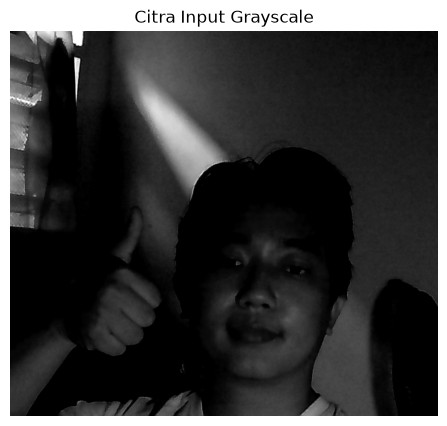

In [52]:
if not GAMBAR_PATH.exists():
    raise FileNotFoundError(
        f"Gambar tidak ditemukan: {GAMBAR_PATH}. "
        "Letakkan gambar di folder notebook dan periksa kembali GAMBAR_PATH."
    )

with Image.open(GAMBAR_PATH) as gambar:
    citra_asli = np.array(gambar.convert("L"), dtype=np.uint8)

print(f"Ukuran citra            : {citra_asli.shape[1]} x {citra_asli.shape[0]} piksel")
print(f"Intensitas minimum      : {citra_asli.min()}")
print(f"Intensitas maksimum     : {citra_asli.max()}")
print(f"Rata-rata intensitas    : {citra_asli.mean():.2f}")

plt.figure(figsize=(8, 5))
plt.imshow(citra_asli, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Input Grayscale")
plt.axis("off")
plt.show()

## 4. Transformasi logaritmik

Rumus pada materi:

$$G = c \cdot \log(F + 1)$$

Konstanta dipilih sebagai berikut agar nilai input maksimum 255 dipetakan menjadi nilai output maksimum 255:

$$c = \frac{255}{\log(256)}$$

Penambahan 1 mencegah perhitungan $\log(0)$.

In [53]:
def transformasi_log(citra):
    tinggi, lebar = citra.shape
    hasil = np.zeros((tinggi, lebar), dtype=np.uint8)
    c = NILAI_MAKSIMUM / math.log(NILAI_MAKSIMUM + 1)

    # Implementasi manual untuk setiap piksel F(x, y).
    for y in range(tinggi):
        for x in range(lebar):
            f = int(citra[y, x])
            g = c * math.log(f + 1)
            hasil[y, x] = np.uint8(round(min(max(g, 0), NILAI_MAKSIMUM)))

    return hasil, c

## 5. Transformasi pangkat (gamma correction)

Rumus pada materi:

$$s = c \cdot r^{\gamma}$$

Nilai piksel $r$ dinormalisasi dari 0-255 menjadi 0-1. Karena hasil pangkat masih berada pada 0-1, digunakan $c=255$ untuk mengembalikannya ke citra 8-bit. Nilai $\gamma < 1$ mengekspansi nilai piksel gelap.

In [54]:
def transformasi_gamma(citra, gamma):
    if not 0 < gamma < 1:
        raise ValueError("Gamma harus memenuhi 0 < gamma < 1.")

    tinggi, lebar = citra.shape
    hasil = np.zeros((tinggi, lebar), dtype=np.uint8)
    c = NILAI_MAKSIMUM

    # Implementasi manual untuk setiap piksel r(x, y).
    for y in range(tinggi):
        for x in range(lebar):
            r = int(citra[y, x]) / NILAI_MAKSIMUM
            s = c * (r ** gamma)
            hasil[y, x] = np.uint8(round(min(max(s, 0), NILAI_MAKSIMUM)))

    return hasil

## 6. Menjalankan kedua transformasi

In [55]:
hasil_log, c_log = transformasi_log(citra_asli)
hasil_gamma = transformasi_gamma(citra_asli, GAMMA)

print(f"Konstanta log (c)       : {c_log:.4f}")
print(f"Nilai gamma             : {GAMMA}")
print(f"Rata-rata citra asli    : {citra_asli.mean():.2f}")
print(f"Rata-rata hasil log     : {hasil_log.mean():.2f}")
print(f"Rata-rata hasil gamma   : {hasil_gamma.mean():.2f}")

Konstanta log (c)       : 45.9859
Nilai gamma             : 0.5
Rata-rata citra asli    : 30.44
Rata-rata hasil log     : 113.73
Rata-rata hasil gamma   : 68.86


## 7. Menampilkan dan menyimpan perbandingan hasil

Parameter `vmin=0` dan `vmax=255` digunakan agar ketiga panel memakai skala grayscale yang sama sehingga perbandingan tidak menyesatkan.

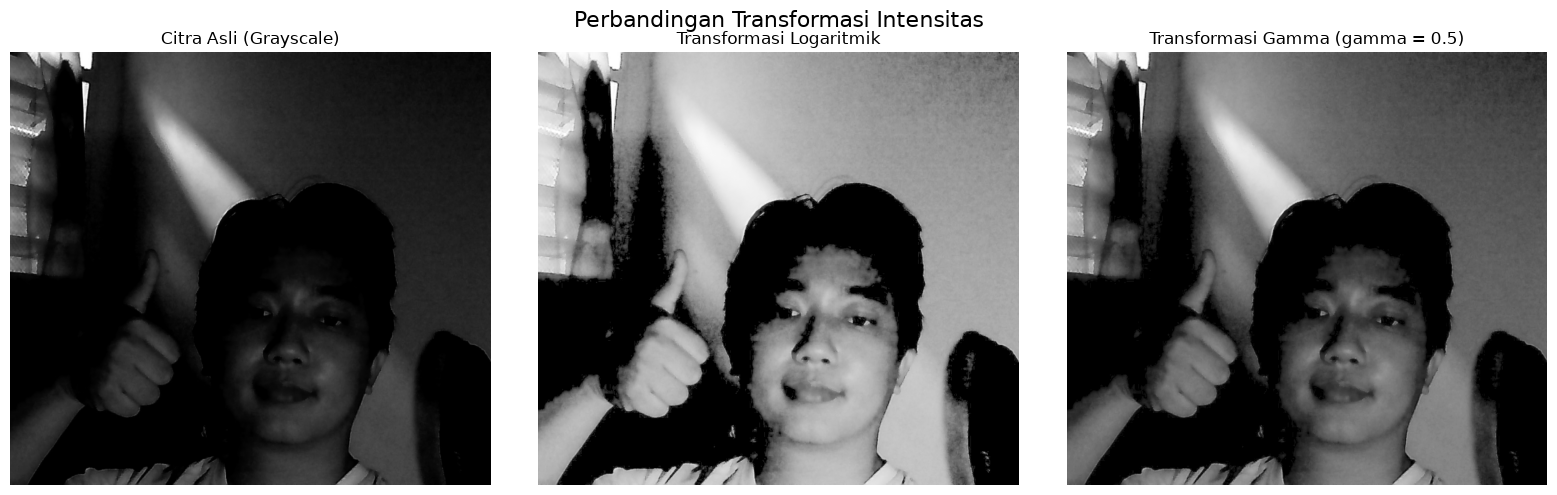

Hasil tersimpan di: /home/oktaavsm/Code/github.com/college/comvis-workspace/notebooks/hasil_output


In [56]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Image.fromarray(hasil_log).save(OUTPUT_DIR / "hasil_log.png")
Image.fromarray(hasil_gamma).save(OUTPUT_DIR / "hasil_gamma.png")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
daftar_citra = [citra_asli, hasil_log, hasil_gamma]
daftar_judul = [
    "Citra Asli (Grayscale)",
    "Transformasi Logaritmik",
    f"Transformasi Gamma (gamma = {GAMMA})",
]

for axis, citra, judul in zip(axes, daftar_citra, daftar_judul):
    axis.imshow(citra, cmap="gray", vmin=0, vmax=255)
    axis.set_title(judul)
    axis.axis("off")

fig.suptitle("Perbandingan Transformasi Intensitas", fontsize=16)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "perbandingan.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Hasil tersimpan di: {OUTPUT_DIR.resolve()}")

## 8. Kesimpulan

Pada umumnya, **transformasi logaritmik** memberikan peningkatan yang lebih kuat pada bagian yang sangat gelap, tetapi bagian tertentu dapat terlihat terlalu terang. **Gamma correction** dengan $\gamma=0.5$ biasanya menghasilkan pencahayaan yang lebih terkendali dan natural.